In [2]:
from pathlib import Path
from collections import Counter
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Dataset path
root = Path(r"D:\AMME5710_Major_Project\dataset")

# Defect categories
classes = [
    "blackspot",
    "colorshift",
    "hair",
    "line",
    "pinhole"
]

# Check train and val folders
for split in ["train", "val"]:
    folder = root / split / "B"
    files = list(folder.glob("*.png"))

    counts = Counter(
        p.name.split("_")[0] for p in files
    )

    print(f"\n{split}: {len(files)} images")

    for category in classes:
        print(f"  {category}: {counts[category]}")



train: 4267 images
  blackspot: 1262
  colorshift: 1380
  hair: 836
  line: 143
  pinhole: 328

val: 523 images
  blackspot: 158
  colorshift: 163
  hair: 105
  line: 17
  pinhole: 41


In [10]:
def extract_features(A, B, mask):

    # 1. Find defect pixels
    gt = mask > 0

    if not np.any(gt):
        return None

    ys, xs = np.where(gt)

    # 2. Calculate bounding box
    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()

    width = x_max - x_min + 1
    height = y_max - y_min + 1

    # 3. Add some surrounding context
    pad = 8

    x1 = max(0, x_min - pad)
    x2 = min(B.shape[1], x_max + pad + 1)
    y1 = max(0, y_min - pad)
    y2 = min(B.shape[0], y_max + pad + 1)

    # 4. Calculate colour difference
    diff = cv2.absdiff(A, B)

    diff_crop = diff[y1:y2, x1:x2]

    # 5. HOG features
    diff_gray = cv2.cvtColor(
        diff_crop, cv2.COLOR_BGR2GRAY
    )

    diff_resized = cv2.resize(
        diff_gray, (32, 32),
        interpolation=cv2.INTER_AREA
    )

    hog_features = hog(
        diff_resized,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    # 6. Colour features inside defect mask
    defect_pixels = diff[gt].astype(np.float32)

    colour_features = np.concatenate([
        defect_pixels.mean(axis=0) / 255.0,
        defect_pixels.std(axis=0) / 255.0
    ])

    # 7. Shape features
    area = np.count_nonzero(gt)

    shape_features = np.array([
        area / gt.size,
        width / B.shape[1],
        height / B.shape[0],
        width / max(height, 1)
    ], dtype=np.float32)

    # 8. Combine all features
    features = np.concatenate([
        hog_features,
        colour_features,
        shape_features
    ])

    return features


In [12]:
def build_features(split):

    X = []
    y = []

    files = sorted(
        (root / split / "B").glob("*.png")
    )

    for index, b_path in enumerate(files):

        filename = b_path.name
        category = filename.split("_")[0]

        if category not in classes:
            continue

        A = cv2.imread(
            str(root / split / "A" / filename)
        )

        B = cv2.imread(str(b_path))

        GT = cv2.imread(
            str(root / split / "OUT" / filename),
            cv2.IMREAD_GRAYSCALE
        )

        if A is None or B is None or GT is None:
            raise FileNotFoundError(filename)

        if A.shape != B.shape or A.shape[:2] != GT.shape:
            raise ValueError(f"Shape mismatch: {filename}")

        features = extract_features(A, B, GT)

        if features is None:
            continue

        X.append(features)
        y.append(category)

        if (index + 1) % 500 == 0:
            print(f"{split}: {index + 1}/{len(files)}")

    return np.asarray(X), np.asarray(y)


# Build training and validation data
X_train, y_train = build_features("train")
X_val, y_val = build_features("val")

print("\nTraining feature matrix:", X_train.shape)
print("Validation feature matrix:", X_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)


train: 500/4267
train: 1000/4267
train: 1500/4267
train: 2000/4267
train: 2500/4267
train: 3000/4267
train: 3500/4267
train: 4000/4267
val: 500/523

Training feature matrix: (3949, 334)
Validation feature matrix: (484, 334)
Training labels: (3949,)
Validation labels: (484,)


SVM training completed!

Validation Accuracy: 0.9401

Classification Report:
              precision    recall  f1-score   support

   blackspot       0.96      0.91      0.94       158
  colorshift       0.94      1.00      0.97       163
        hair       0.98      0.96      0.97       105
        line       1.00      0.82      0.90        17
     pinhole       0.75      0.80      0.78        41

    accuracy                           0.94       484
   macro avg       0.93      0.90      0.91       484
weighted avg       0.94      0.94      0.94       484



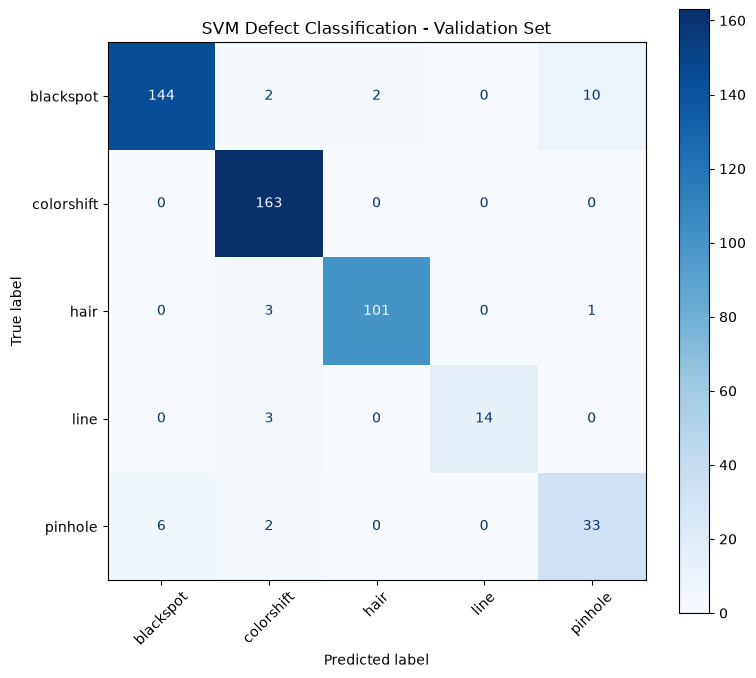

In [13]:
# Build baseline SVM classifier
model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42
    )
)

# Train model
model.fit(X_train, y_train)

print("SVM training completed!")

# Predict validation labels
y_pred = model.predict(X_val)

# Evaluate classification
accuracy = accuracy_score(y_val, y_pred)

print(f"\nValidation Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred,
        labels=classes,
        zero_division=0
    )
)

# Confusion matrix
fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=classes,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("SVM Defect Classification - Validation Set")
plt.tight_layout()
plt.show()


In [14]:
import joblib

joblib.dump(
    model,
    root.parent / "svm_classes.joblib"
)

print("Five-class SVM saved successfully!")

Five-class SVM saved successfully!


In [15]:
# Classification using RGB-predicted defect masks

X_val_rgb = []
y_val_rgb = []
missing_detection = []

files = sorted((root / "val" / "B").glob("*.png"))

T_rgb = 40  # Best RGB threshold from validation

for b_path in files:

    filename = b_path.name
    category = filename.split("_")[0]

    A = cv2.imread(
        str(root / "val" / "A" / filename)
    )

    B = cv2.imread(str(b_path))

    if A is None or B is None:
        raise FileNotFoundError(filename)

    # Generate RGB predicted mask
    colour_diff = cv2.absdiff(A, B)
    diff = np.max(colour_diff, axis=2)

    pred_mask = (diff > T_rgb).astype(np.uint8) * 255

    # Extract features using predicted mask
    # No Ground Truth used here
    features = extract_features(A, B, pred_mask)

    if features is None:
        missing_detection.append(filename)
        continue

    X_val_rgb.append(features)
    y_val_rgb.append(category)

X_val_rgb = np.asarray(X_val_rgb)
y_val_rgb = np.asarray(y_val_rgb)

print("Images with extracted features:", len(X_val_rgb))
print("Images with no detected pixels:", len(missing_detection))

# Predict with the existing trained SVM
if len(X_val_rgb) > 0:
    y_pred_rgb = model.predict(X_val_rgb)

    print("\nClassification with RGB predicted masks:")
    print(classification_report(
        y_val_rgb,
        y_pred_rgb,
        labels=classes,
        zero_division=0
    ))

    correct = np.sum(y_pred_rgb == y_val_rgb)

    print(
        "Accuracy on images with a predicted mask:",
        round(correct / len(y_val_rgb), 4)
    )

    print(
        "Correct classifications / all validation images:",
        round(correct / len(files), 4)
    )


Images with extracted features: 518
Images with no detected pixels: 5

Classification with RGB predicted masks:
              precision    recall  f1-score   support

   blackspot       0.92      0.43      0.59       158
  colorshift       0.45      1.00      0.62       163
        hair       0.92      0.47      0.62       105
        line       0.67      0.33      0.44        12
     pinhole       0.88      0.51      0.65        41

   micro avg       0.59      0.64      0.61       479
   macro avg       0.77      0.55      0.58       479
weighted avg       0.75      0.64      0.61       479

Accuracy on images with a predicted mask: 0.5888
Correct classifications / all validation images: 0.5832


test: 500/533
Test features shape: (492, 334)
Test categories: Counter({np.str_('colorshift'): 169, np.str_('blackspot'): 158, np.str_('hair'): 105, np.str_('pinhole'): 42, np.str_('line'): 18})

Five-class Test Accuracy:
0.9491869918699187

Classification Report:
              precision    recall  f1-score   support

   blackspot       0.99      0.90      0.94       158
  colorshift       0.97      0.99      0.98       169
        hair       0.95      0.99      0.97       105
        line       0.94      0.94      0.94        18
     pinhole       0.76      0.88      0.81        42

    accuracy                           0.95       492
   macro avg       0.92      0.94      0.93       492
weighted avg       0.95      0.95      0.95       492



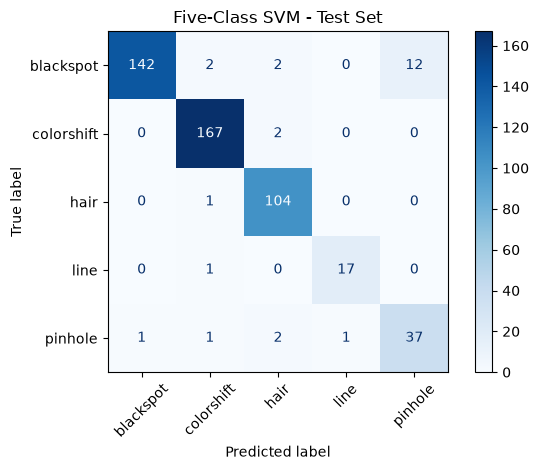

In [16]:
# Extract features from the test set
X_test, y_test = build_features("test")

print("Test features shape:", X_test.shape)
print("Test categories:", Counter(y_test))

# Predict using the trained five-class SVM
y_test_pred = model.predict(X_test)

# Evaluate classification performance
print("\nFive-class Test Accuracy:")
print(accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=classes,
    zero_division=0
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=classes,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Five-Class SVM - Test Set")
plt.tight_layout()
plt.show()


In [17]:
import pandas as pd

# Extract shape features from training samples
feature_df = pd.DataFrame({
    "Class": y_train,
    "Area ratio": X_train[:, 330],
    "Aspect ratio": X_train[:, 333]
})

# Calculate median and interquartile range
summary = feature_df.groupby("Class").agg(
    Area_median=("Area ratio", "median"),
    Area_Q25=("Area ratio", lambda x: x.quantile(0.25)),
    Area_Q75=("Area ratio", lambda x: x.quantile(0.75)),
    Aspect_median=("Aspect ratio", "median"),
    Aspect_Q25=("Aspect ratio", lambda x: x.quantile(0.25)),
    Aspect_Q75=("Aspect ratio", lambda x: x.quantile(0.75))
)

print("Training Feature Distribution:")
display(summary.round(4))


Training Feature Distribution:


,Area_median,Area_Q25,Area_Q75,Aspect_median,Aspect_Q25,Aspect_Q75
Class,,,,,,
blackspot,0.0063,0.0049,0.0077,1.0000,0.8667,1.1635
colorshift,0.1856,0.1136,0.2725,1.2549,1.0000,1.7297
hair,0.0114,0.0087,0.0157,1.0000,0.7200,1.4500
line,0.0143,0.0088,0.0219,0.0742,0.0469,0.1083
pinhole,0.0052,0.0043,0.0062,1.0000,0.7273,1.2893
